# Gene Agent LangGraph 展示

这个 notebook 用当前代码里的 LangGraph builder 直接渲染系统父图和各个子图。
适合在组会、交接、方案评审时快速说明：父图只负责调度，业务逻辑下沉到 stage
subgraph，具体可执行方法再下沉到 method-application subgraph。

> 运行环境建议使用项目的 `gene_agent` conda 环境。


## 1. 导入构图函数

这里 notebook 展示的是当前仓库的真实 LangGraph 结构。


In [1]:
from __future__ import annotations

import inspect
from collections import OrderedDict

from IPython.display import Image, Markdown, display

from app.graph.builder import build_graph
from app.stages.assembly.builder import build_stage as build_assembly_stage
from app.stages.assembly.method_application import (
    build_flye_graph,
    build_nextdenovo_graph,
)
from app.stages.assembly_review.builder import build_stage as build_assembly_review_stage
from app.stages.function_annotation.builder import build_stage as build_function_annotation_stage
from app.stages.gene_annotation.builder import build_stage as build_gene_annotation_stage
from app.stages.genome_survey.builder import build_stage as build_genome_survey_stage
from app.stages.hic_scaffolding.builder import build_stage as build_hic_scaffolding_stage
from app.stages.hic_scaffolding.method_application import (
    build_juicer_3ddna_graph,
    build_yahs_graph,
)
from app.stages.inventory.builder import build_stage as build_inventory_stage
from app.stages.read_qc.builder import build_stage as build_read_qc_stage
from app.stages.repeat_annotation.builder import build_stage as build_repeat_annotation_stage


## 2. 渲染 helper

`render_graph()` 优先使用 LangGraph 的 `draw_mermaid_png()` 展示图片；如果当前环境缺少
PNG 渲染能力，会自动退回到 Mermaid 源码，仍然可以复制到 Mermaid Live Editor 或 Markdown
渲染器里查看。


In [2]:
def builder_source(builder) -> str:
    try:
        return inspect.getsourcefile(builder) or "unknown"
    except TypeError:
        return "unknown"


def render_graph(title: str, compiled_graph, *, xray: bool = False) -> None:
    graph = compiled_graph.get_graph(xray=xray)
    display(Markdown(f"### {title}"))
    display(Markdown(f"Nodes: `{len(graph.nodes)}` · Edges: `{len(graph.edges)}` · xray: `{xray}`"))
    try:
        display(Image(data=graph.draw_mermaid_png()))
    except Exception as exc:  # pragma: no cover - notebook display fallback
        display(Markdown(f"PNG render unavailable: `{type(exc).__name__}: {exc}`"))
        display(Markdown("```mermaid\n" + graph.draw_mermaid() + "\n```"))


parent_graph = build_graph(backend="memory")

STAGE_GRAPHS = OrderedDict(
    [
        ("inventory", build_inventory_stage),
        ("read_qc", build_read_qc_stage),
        ("genome_survey", build_genome_survey_stage),
        ("assembly", build_assembly_stage),
        ("assembly_review", build_assembly_review_stage),
        ("hic_scaffolding", build_hic_scaffolding_stage),
        ("repeat_annotation", build_repeat_annotation_stage),
        ("gene_annotation", build_gene_annotation_stage),
        ("function_annotation", build_function_annotation_stage),
    ]
)

METHOD_GRAPHS = OrderedDict(
    [
        ("assembly.method.flye", build_flye_graph),
        ("assembly.method.nextdenovo", build_nextdenovo_graph),
        ("hic_scaffolding.method.juicer_3ddna", build_juicer_3ddna_graph),
        ("hic_scaffolding.method.yahs", build_yahs_graph),
    ]
)


## 3. 系统父图

父图保持很薄：`route_controller` 根据 `current_stage` 调度固定 stage，
每个 stage 返回后再回到 `route_controller`。父图不做生信方法选择，也不执行工具。


### Parent graph: thin stage scheduler

Nodes: `14` · Edges: `24` · xray: `False`

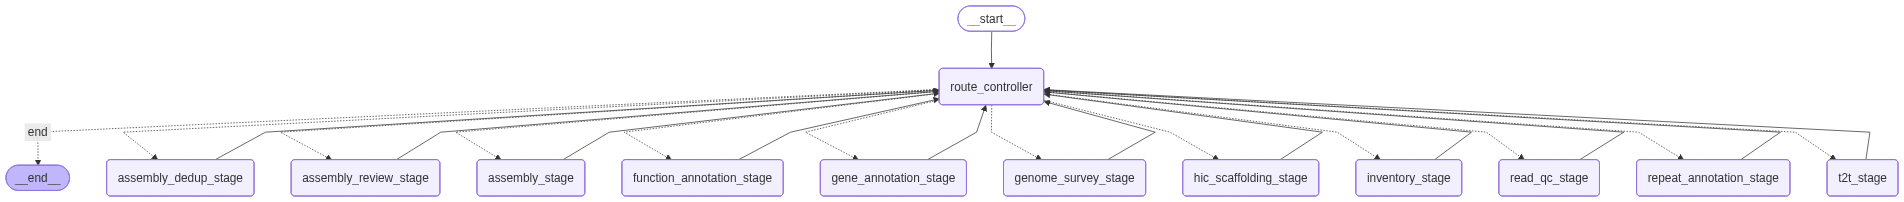

In [3]:
render_graph("Parent graph: thin stage scheduler", parent_graph, xray=False)


## 4. Stage subgraphs

每个 stage subgraph 拥有本阶段的输入校验、计划、执行候选、review/commit/fail/block 路径。


Source: `/Users/a1/Documents/BGIwork/gene_agent/app/stages/inventory/builder.py`

### Stage subgraph: inventory

Nodes: `8` · Edges: `9` · xray: `False`

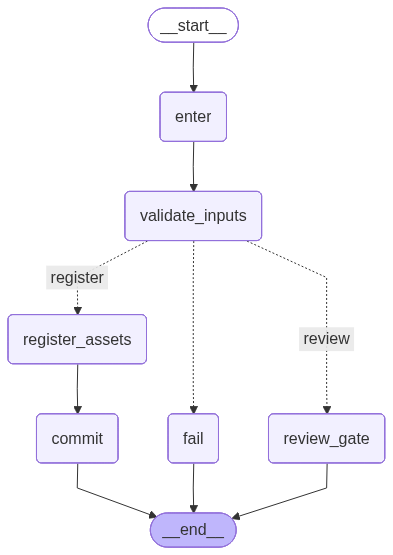

Source: `/Users/a1/Documents/BGIwork/gene_agent/app/stages/read_qc/builder.py`

### Stage subgraph: read_qc

Nodes: `13` · Edges: `20` · xray: `False`

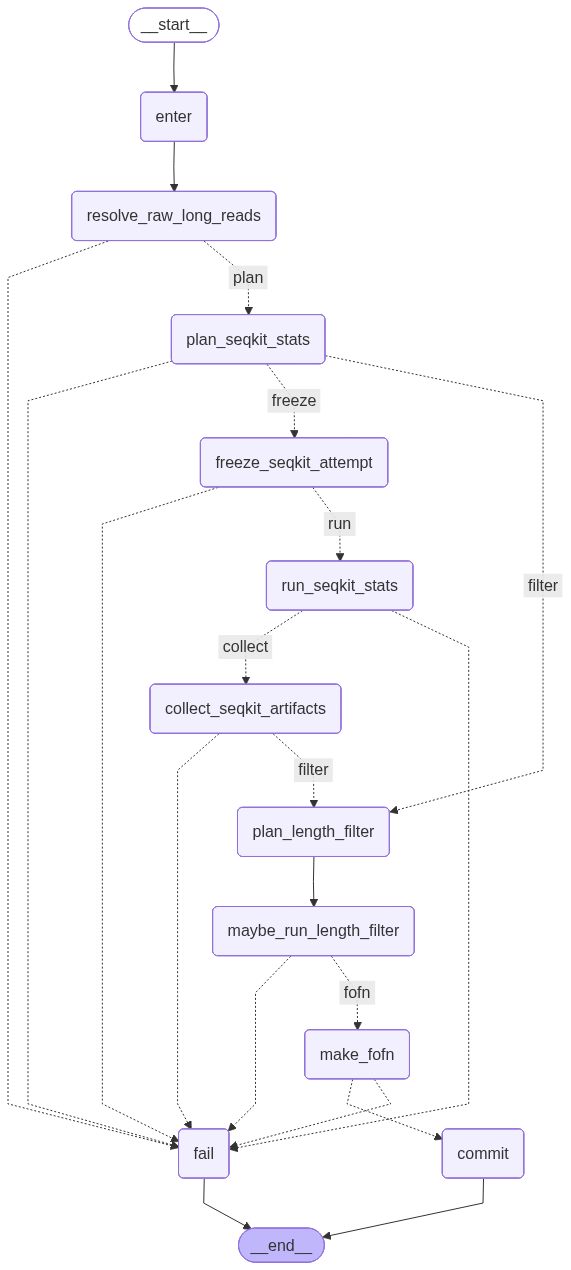

Source: `/Users/a1/Documents/BGIwork/gene_agent/app/stages/genome_survey/builder.py`

### Stage subgraph: genome_survey

Nodes: `17` · Edges: `31` · xray: `False`

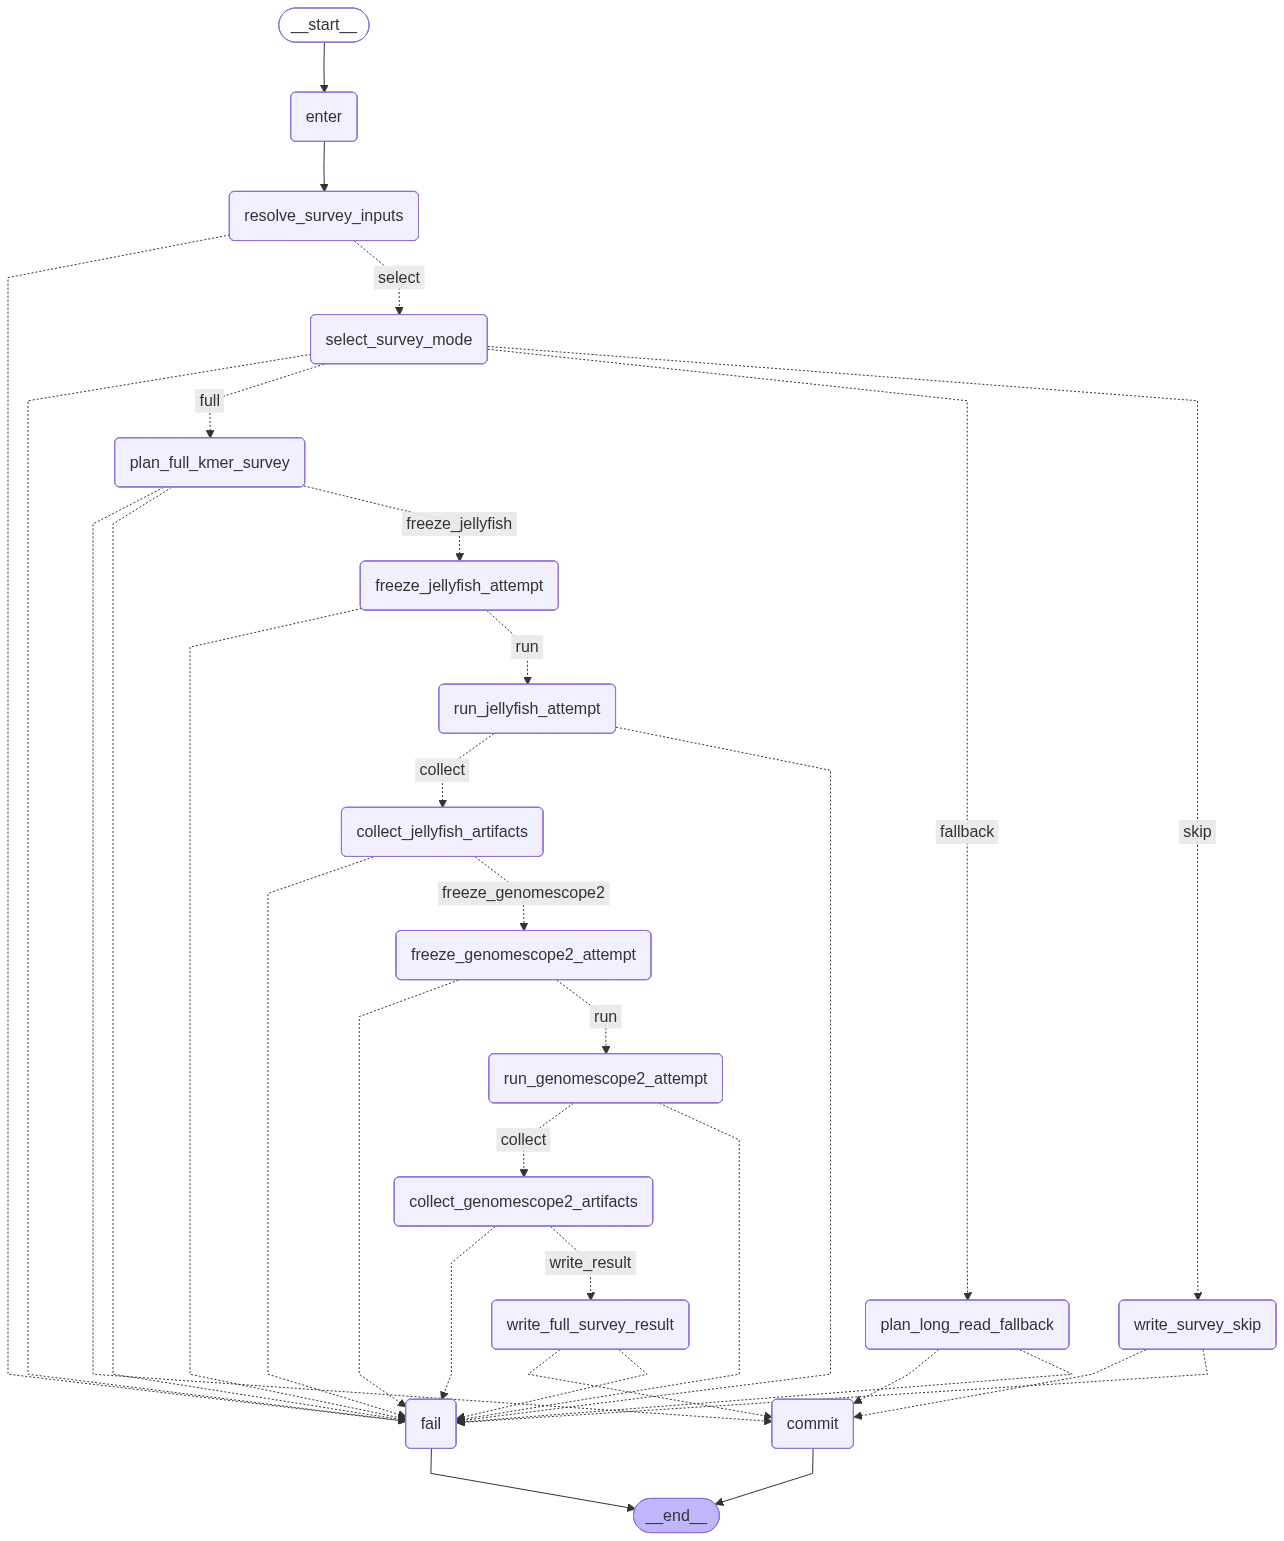

Source: `/Users/a1/Documents/BGIwork/gene_agent/app/stages/assembly/builder.py`

### Stage subgraph: assembly

Nodes: `14` · Edges: `25` · xray: `False`

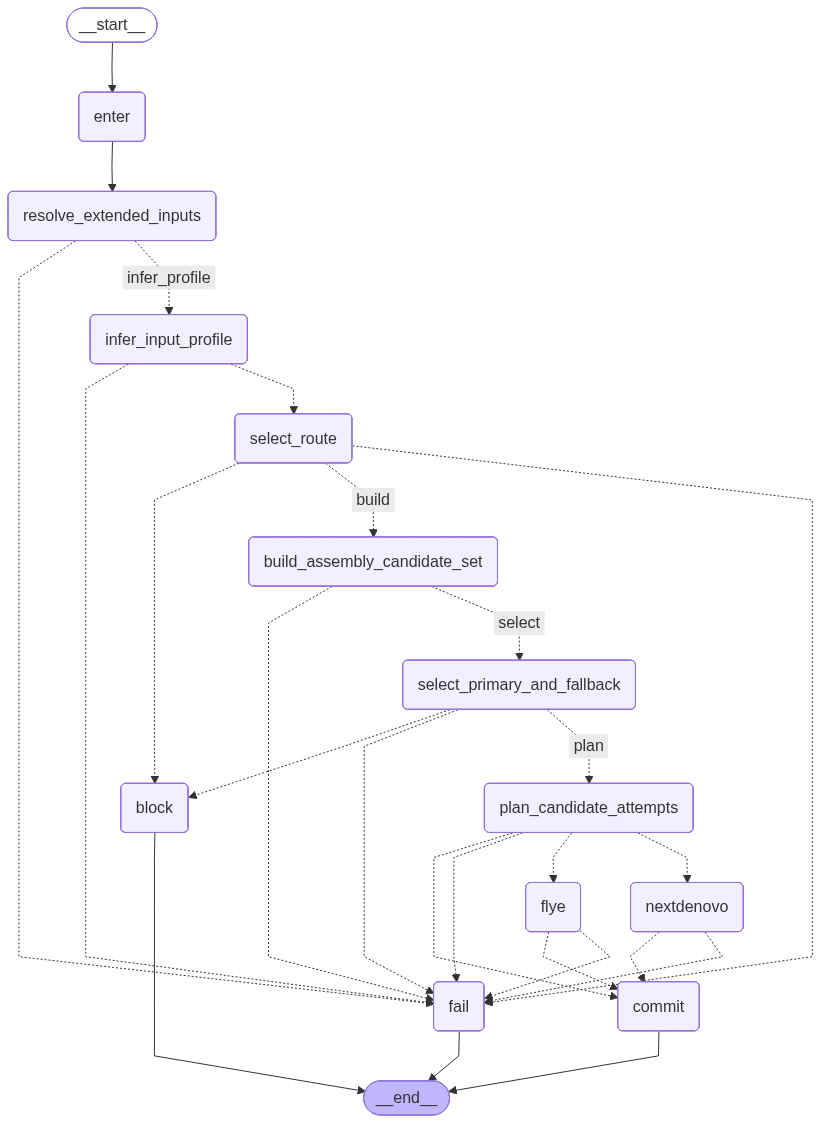

Source: `/Users/a1/Documents/BGIwork/gene_agent/app/stages/assembly_review/builder.py`

### Stage subgraph: assembly_review

Nodes: `15` · Edges: `27` · xray: `False`

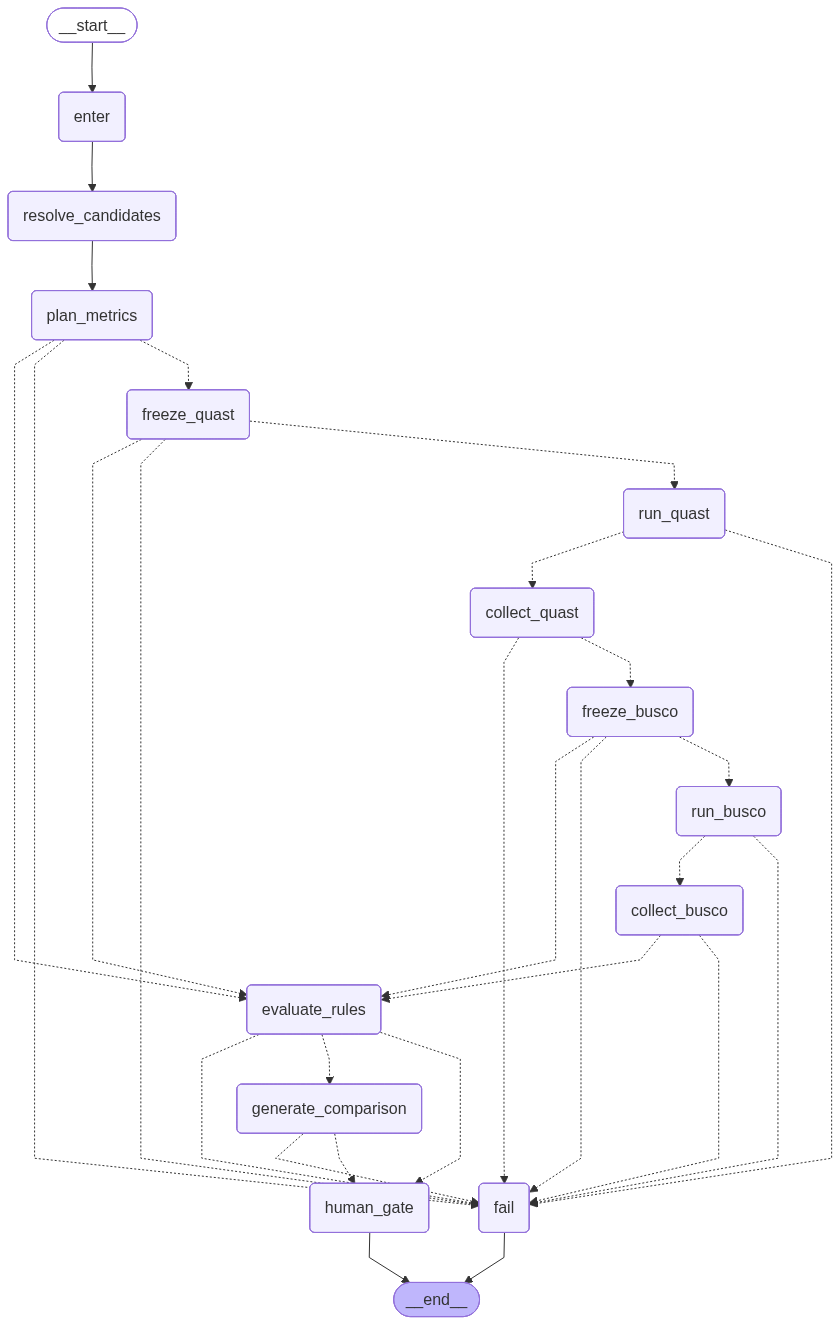

Source: `/Users/a1/Documents/BGIwork/gene_agent/app/stages/hic_scaffolding/builder.py`

### Stage subgraph: hic_scaffolding

Nodes: `12` · Edges: `24` · xray: `False`

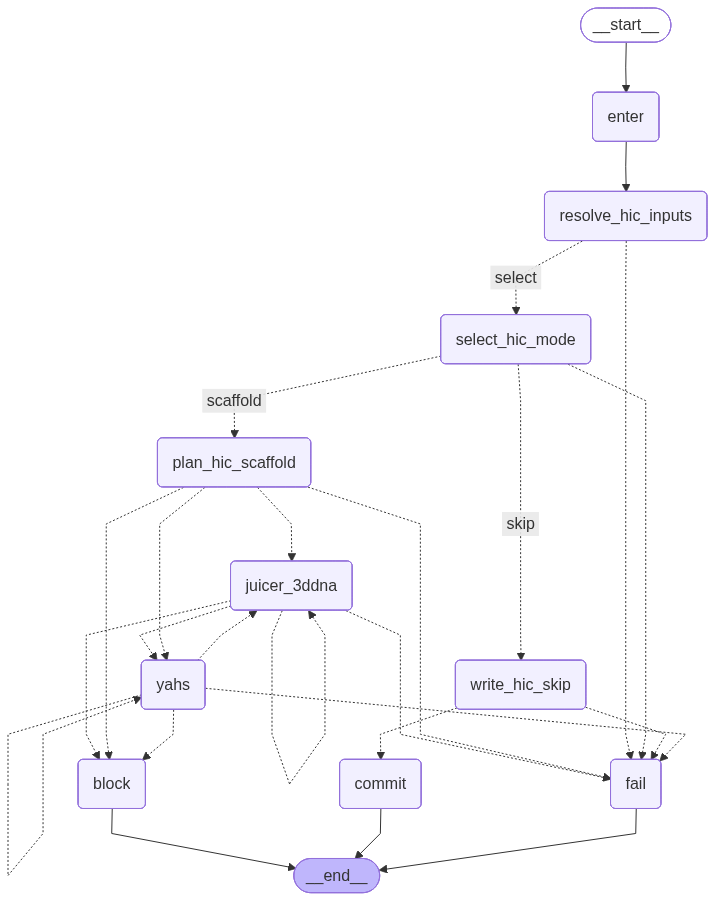

Source: `/Users/a1/Documents/BGIwork/gene_agent/app/stages/repeat_annotation/builder.py`

### Stage subgraph: repeat_annotation

Nodes: `13` · Edges: `20` · xray: `False`

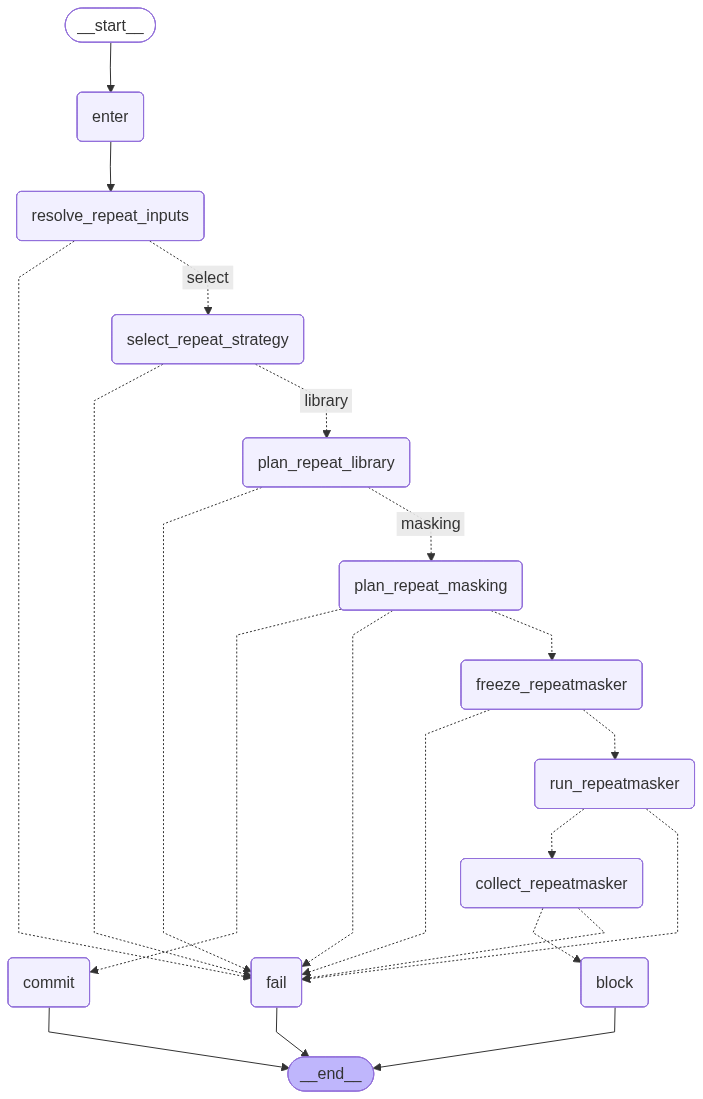

Source: `/Users/a1/Documents/BGIwork/gene_agent/app/stages/gene_annotation/builder.py`

### Stage subgraph: gene_annotation

Nodes: `26` · Edges: `77` · xray: `False`

PNG render unavailable: `ValueError: Failed to reach https://mermaid.ink API while trying to render your graph. Status code: 414.

To resolve this issue:
1. Check your internet connection and try again
2. Try with higher retry settings: `draw_mermaid_png(..., max_retries=5, retry_delay=2.0)`
3. Use the Pyppeteer rendering method which will render your graph locally in a browser: `draw_mermaid_png(..., draw_method=MermaidDrawMethod.PYPPETEER)``

```mermaid
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	enter(enter)
	resolve_gene_annotation_inputs(resolve_gene_annotation_inputs)
	select_evidence_profile(select_evidence_profile)
	plan_gene_methods(plan_gene_methods)
	block_gene_method_planning_review(block_gene_method_planning_review)
	run_gene_methods_planning_only(run_gene_methods_planning_only)
	freeze_miniprot_attempt(freeze_miniprot_attempt)
	run_miniprot_attempt(run_miniprot_attempt)
	collect_miniprot_artifacts(collect_miniprot_artifacts)
	freeze_augustus_attempt(freeze_augustus_attempt)
	run_augustus_attempt(run_augustus_attempt)
	collect_augustus_artifacts(collect_augustus_artifacts)
	freeze_evm_attempt(freeze_evm_attempt)
	run_evm_attempt(run_evm_attempt)
	collect_evm_artifacts(collect_evm_artifacts)
	freeze_gene_busco_attempt(freeze_gene_busco_attempt)
	run_gene_busco_attempt(run_gene_busco_attempt)
	collect_gene_busco_artifacts(collect_gene_busco_artifacts)
	block_candidate_evidence_review(block_candidate_evidence_review)
	plan_evidence_merge_or_review(plan_evidence_merge_or_review)
	block_merge_review(block_merge_review)
	block_final_gene_set_review(block_final_gene_set_review)
	commit(commit)
	fail(fail)
	__end__([<p>__end__</p>]):::last
	__start__ --> enter;
	block_candidate_evidence_review -. &nbsp;end&nbsp; .-> __end__;
	block_candidate_evidence_review -.-> fail;
	block_candidate_evidence_review -. &nbsp;merge_prep&nbsp; .-> plan_evidence_merge_or_review;
	block_candidate_evidence_review -. &nbsp;run_methods&nbsp; .-> run_gene_methods_planning_only;
	block_final_gene_set_review -. &nbsp;end&nbsp; .-> __end__;
	block_final_gene_set_review -.-> commit;
	block_final_gene_set_review -.-> fail;
	block_final_gene_set_review -. &nbsp;merge_prep&nbsp; .-> plan_evidence_merge_or_review;
	block_gene_method_planning_review -. &nbsp;end&nbsp; .-> __end__;
	block_gene_method_planning_review -.-> fail;
	block_gene_method_planning_review -. &nbsp;run_methods&nbsp; .-> run_gene_methods_planning_only;
	block_merge_review -. &nbsp;end&nbsp; .-> __end__;
	block_merge_review -. &nbsp;block_final&nbsp; .-> block_final_gene_set_review;
	block_merge_review -.-> fail;
	block_merge_review -. &nbsp;evm_freeze&nbsp; .-> freeze_evm_attempt;
	collect_augustus_artifacts -. &nbsp;block_candidates&nbsp; .-> block_candidate_evidence_review;
	collect_augustus_artifacts -.-> fail;
	collect_augustus_artifacts -. &nbsp;run_methods&nbsp; .-> run_gene_methods_planning_only;
	collect_evm_artifacts -.-> fail;
	collect_evm_artifacts -. &nbsp;busco_freeze&nbsp; .-> freeze_gene_busco_attempt;
	collect_gene_busco_artifacts -. &nbsp;block_final&nbsp; .-> block_final_gene_set_review;
	collect_miniprot_artifacts -. &nbsp;block_candidates&nbsp; .-> block_candidate_evidence_review;
	collect_miniprot_artifacts -.-> fail;
	collect_miniprot_artifacts -. &nbsp;run_methods&nbsp; .-> run_gene_methods_planning_only;
	enter -.-> fail;
	enter -. &nbsp;resolve&nbsp; .-> resolve_gene_annotation_inputs;
	freeze_augustus_attempt -.-> fail;
	freeze_augustus_attempt -. &nbsp;augustus_run&nbsp; .-> run_augustus_attempt;
	freeze_evm_attempt -.-> fail;
	freeze_evm_attempt -. &nbsp;busco_freeze&nbsp; .-> freeze_gene_busco_attempt;
	freeze_evm_attempt -. &nbsp;evm_run&nbsp; .-> run_evm_attempt;
	freeze_gene_busco_attempt -. &nbsp;block_final&nbsp; .-> block_final_gene_set_review;
	freeze_gene_busco_attempt -.-> fail;
	freeze_gene_busco_attempt -. &nbsp;busco_run&nbsp; .-> run_gene_busco_attempt;
	freeze_miniprot_attempt -.-> fail;
	freeze_miniprot_attempt -. &nbsp;miniprot_run&nbsp; .-> run_miniprot_attempt;
	plan_evidence_merge_or_review -. &nbsp;block_merge&nbsp; .-> block_merge_review;
	plan_evidence_merge_or_review -.-> fail;
	plan_gene_methods -. &nbsp;block_candidates&nbsp; .-> block_candidate_evidence_review;
	plan_gene_methods -. &nbsp;block_final&nbsp; .-> block_final_gene_set_review;
	plan_gene_methods -. &nbsp;block_method&nbsp; .-> block_gene_method_planning_review;
	plan_gene_methods -. &nbsp;block_merge&nbsp; .-> block_merge_review;
	plan_gene_methods -. &nbsp;evm_collect&nbsp; .-> collect_evm_artifacts;
	plan_gene_methods -. &nbsp;busco_collect&nbsp; .-> collect_gene_busco_artifacts;
	plan_gene_methods -.-> commit;
	plan_gene_methods -.-> fail;
	plan_gene_methods -. &nbsp;evm_freeze&nbsp; .-> freeze_evm_attempt;
	plan_gene_methods -. &nbsp;busco_freeze&nbsp; .-> freeze_gene_busco_attempt;
	plan_gene_methods -. &nbsp;merge_prep&nbsp; .-> plan_evidence_merge_or_review;
	plan_gene_methods -. &nbsp;evm_run&nbsp; .-> run_evm_attempt;
	plan_gene_methods -. &nbsp;busco_run&nbsp; .-> run_gene_busco_attempt;
	plan_gene_methods -. &nbsp;run_methods&nbsp; .-> run_gene_methods_planning_only;
	resolve_gene_annotation_inputs -.-> commit;
	resolve_gene_annotation_inputs -.-> fail;
	resolve_gene_annotation_inputs -. &nbsp;profile&nbsp; .-> select_evidence_profile;
	run_augustus_attempt -. &nbsp;augustus_collect&nbsp; .-> collect_augustus_artifacts;
	run_augustus_attempt -.-> fail;
	run_evm_attempt -. &nbsp;evm_collect&nbsp; .-> collect_evm_artifacts;
	run_evm_attempt -.-> fail;
	run_gene_busco_attempt -. &nbsp;block_final&nbsp; .-> block_final_gene_set_review;
	run_gene_busco_attempt -. &nbsp;busco_collect&nbsp; .-> collect_gene_busco_artifacts;
	run_gene_busco_attempt -.-> fail;
	run_gene_methods_planning_only -. &nbsp;block_candidates&nbsp; .-> block_candidate_evidence_review;
	run_gene_methods_planning_only -. &nbsp;augustus_collect&nbsp; .-> collect_augustus_artifacts;
	run_gene_methods_planning_only -. &nbsp;miniprot_collect&nbsp; .-> collect_miniprot_artifacts;
	run_gene_methods_planning_only -.-> fail;
	run_gene_methods_planning_only -. &nbsp;augustus_freeze&nbsp; .-> freeze_augustus_attempt;
	run_gene_methods_planning_only -. &nbsp;miniprot_freeze&nbsp; .-> freeze_miniprot_attempt;
	run_gene_methods_planning_only -. &nbsp;augustus_run&nbsp; .-> run_augustus_attempt;
	run_gene_methods_planning_only -. &nbsp;miniprot_run&nbsp; .-> run_miniprot_attempt;
	run_miniprot_attempt -. &nbsp;miniprot_collect&nbsp; .-> collect_miniprot_artifacts;
	run_miniprot_attempt -.-> fail;
	select_evidence_profile -.-> fail;
	select_evidence_profile -. &nbsp;methods&nbsp; .-> plan_gene_methods;
	commit --> __end__;
	fail --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc

```

Source: `/Users/a1/Documents/BGIwork/gene_agent/app/stages/function_annotation/builder.py`

### Stage subgraph: function_annotation

Nodes: `11` · Edges: `20` · xray: `False`

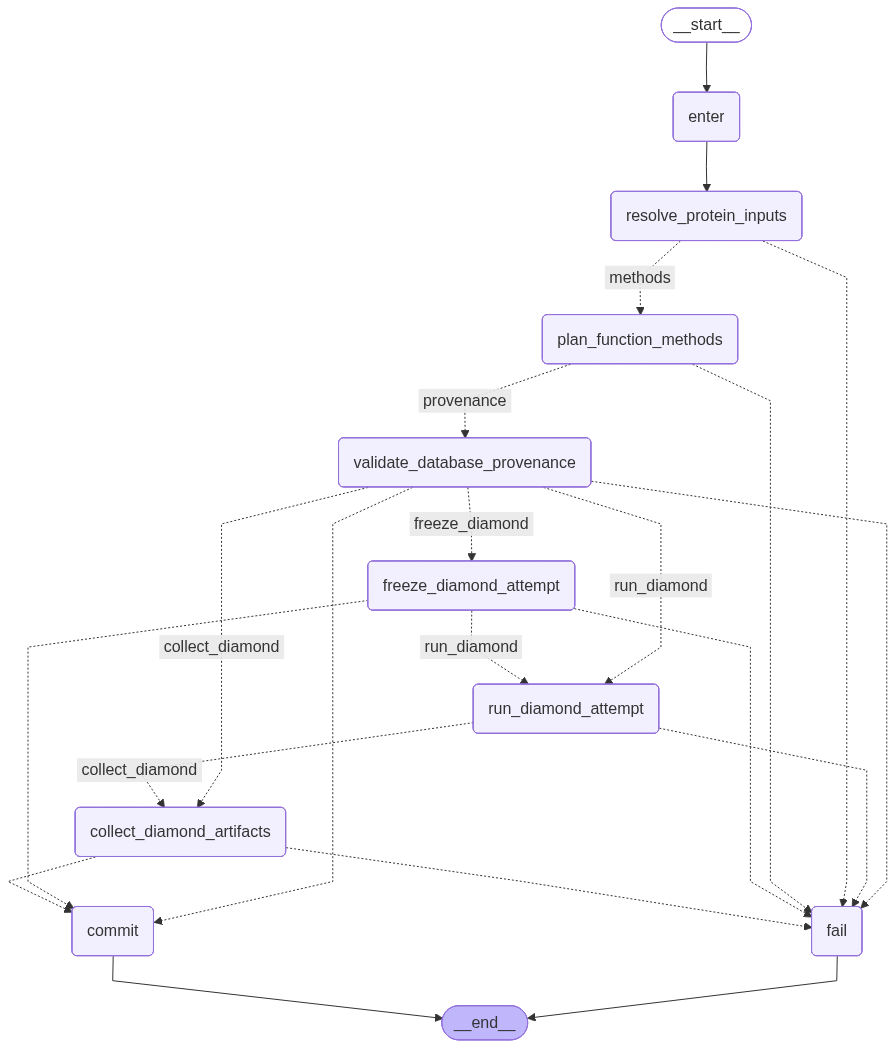

In [4]:
for name, builder in STAGE_GRAPHS.items():
    display(Markdown(f"Source: `{builder_source(builder)}`"))
    render_graph(f"Stage subgraph: {name}", builder(), xray=False)


## 5. Method-application subgraphs

目前可执行方法的公共形态是 `freeze -> run -> collect -> done`。这些 method subgraph
被 stage subgraph 当作普通节点调用，用来隔离具体工具执行和 artifact 收集逻辑。


Source: `/Users/a1/Documents/BGIwork/gene_agent/app/stages/assembly/method_application/flye.py`

### Method subgraph: assembly.method.flye

Nodes: `6` · Edges: `7` · xray: `False`

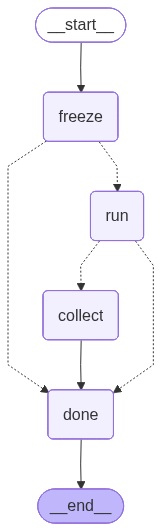

Source: `/Users/a1/Documents/BGIwork/gene_agent/app/stages/assembly/method_application/nextdenovo.py`

### Method subgraph: assembly.method.nextdenovo

Nodes: `6` · Edges: `7` · xray: `False`

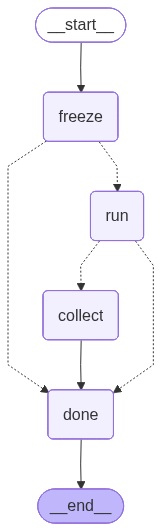

Source: `/Users/a1/Documents/BGIwork/gene_agent/app/stages/hic_scaffolding/method_application/juicer_3ddna.py`

### Method subgraph: hic_scaffolding.method.juicer_3ddna

Nodes: `6` · Edges: `7` · xray: `False`

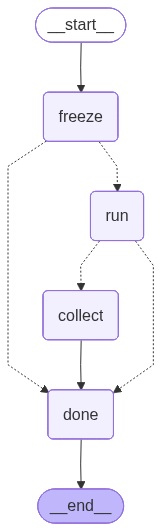

Source: `/Users/a1/Documents/BGIwork/gene_agent/app/stages/hic_scaffolding/method_application/yahs.py`

### Method subgraph: hic_scaffolding.method.yahs

Nodes: `6` · Edges: `7` · xray: `False`

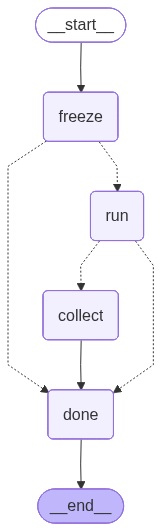

In [5]:
for name, builder in METHOD_GRAPHS.items():
    display(Markdown(f"Source: `{builder_source(builder)}`"))
    render_graph(f"Method subgraph: {name}", builder(), xray=False)


## 6. 讲解要点

- **Parent graph**：只做 stage 调度和 terminal 状态处理，保持薄。
- **Stage subgraph**：承载阶段内的业务边界，例如 assembly 的候选方法规划、Hi-C 的 skip/scaffold 分支。
- **Method subgraph**：承载具体可执行方法的冻结参数、运行、收集 artifact 生命周期。
- **State 原则**：LangGraph state 保存小型控制事实；大文件、日志、指标表通过 ledger / artifact registry 引用。
